# 04 - Optimized CNN+LSTM Training (Two-Stage + Chunking + AMP)

## Objective
Train the CNN+LSTM model with optimizations to prevent overfitting and reduce memory usage.

### Training Strategy: Two-Stage Training

**Problem**: With small datasets, the CNN memorizes training videos before the LSTM learns temporal patterns.

**Solution**: Two-stage training approach:

| Stage | Epochs | CNN | LSTM | Learning Rate |
|-------|--------|-----|------|---------------|
| 1 | 1-15 | Frozen | Training | 1e-3 (higher for LSTM) |
| 2 | 16-100 | Unfrozen | Training | 1e-5 (lower for fine-tuning) |

**Why this works**:
- Stage 1: LSTM must learn temporal patterns from generic ImageNet features
- Stage 2: CNN fine-tunes to recognize hand-specific features (without memorizing)

### Memory Optimizations

1. **Chunked CNN Processing**: Process 64 frames at a time instead of 1024
2. **Automatic Mixed Precision (AMP)**: Float16 for 50% memory reduction

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Environment Setup

In [2]:
import os
from pathlib import Path
from google.colab import drive

# ============================================
# PATH CONFIGURATION
# ============================================

# 1. Local paths (Colab SSD - FAST)
# Using AUGMENTED dataset for better generalization
ZIP_LOCAL = Path("/content/wlasl30_augmented.zip")
DATASET_ROOT = Path("/content/wlasl30_augmented")

# 2. Unzip if not already done
if not DATASET_ROOT.exists():
    if ZIP_LOCAL.exists():
        print(f"📦 Extracting {ZIP_LOCAL} locally...")
        !unzip -q {ZIP_LOCAL} -d /content/
        print("✅ Extraction complete.")
    else:
        print(f"❌ ERROR: Cannot find '{ZIP_LOCAL}'.")
        print("👉 Make sure you've uploaded 'wlasl30_augmented.zip' to the files panel.")
        print("   Or copy from Drive: cp /content/drive/MyDrive/tfg/datasets/wlasl30_augmented.zip /content/")
        raise FileNotFoundError("Missing zip file")
else:
    print("✅ Dataset folder already extracted.")

# 3. Configure where to save results (Drive - persistent)
try:
    drive.mount('/content/drive')
    EXPERIMENTS_DIR = Path("/content/drive/MyDrive/tfg/experiments/word_recognition")
    EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
    print(f"💾 Results will be saved to: {EXPERIMENTS_DIR}")
except:
    print("⚠️ Could not mount Drive. Results will be saved locally (will be deleted on session close).")
    EXPERIMENTS_DIR = Path("/content/experiments")

print(f"\n🎯 DATASET_ROOT: {DATASET_ROOT}")

📦 Extracting /content/wlasl30_augmented.zip locally...
✅ Extraction complete.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
💾 Results will be saved to: /content/drive/MyDrive/tfg/experiments/word_recognition

🎯 DATASET_ROOT: /content/wlasl30_augmented


## 1. Imports and Configuration

In [3]:
import json
import time
from typing import List, Tuple, Dict, Optional
from datetime import datetime

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
from tqdm.auto import tqdm

# Verify GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Total memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"CUDA version: {torch.version.cuda}")

    # Check if bfloat16 is supported (A100, H100, etc.)
    if torch.cuda.is_bf16_supported():
        print("✅ bfloat16 supported (optimal for A100)")
    else:
        print("⚠️ bfloat16 not supported, using float16")

Using device: cuda
GPU: NVIDIA A100-SXM4-40GB
Total memory: 42.5 GB
CUDA version: 12.6
✅ bfloat16 supported (optimal for A100)


## 2. Dataset and DataLoader (Same as before)

In [4]:
# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_transforms(split: str, img_size: int = 224):
    """Transforms for each split.

    NOTE: We do NOT use RandomHorizontalFlip for ASL because
    flipping can change the meaning of signs (changes dominant hand).
    """
    if split == "train":
        return T.Compose([
            T.Resize((img_size, img_size)),
            # NO RandomHorizontalFlip - dangerous for ASL!
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    else:
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])

In [5]:
class WLASLDataset(Dataset):
    """Dataset for loading video sequences from WLASL."""

    def __init__(
        self,
        root_dir: str,
        split: str = "train",
        transform: Optional[T.Compose] = None,
        max_frames: Optional[int] = None,
        sample_strategy: str = "uniform"
    ):
        self.root_dir = Path(root_dir)
        self.split = split
        self.transform = transform
        self.max_frames = max_frames
        self.sample_strategy = sample_strategy

        with open(self.root_dir / "metadata.json", "r") as f:
            self.metadata = json.load(f)

        self.gloss_to_idx = self.metadata["gloss_to_idx"]
        self.idx_to_gloss = {v: k for k, v in self.gloss_to_idx.items()}
        self.num_classes = len(self.gloss_to_idx)
        self.samples = self._build_sample_list()

        print(f"WLASLDataset [{split}]: {len(self.samples)} videos, {self.num_classes} classes")

    def _build_sample_list(self) -> List[Tuple[Path, int]]:
        samples = []
        split_dir = self.root_dir / self.split

        for gloss_dir in sorted(split_dir.iterdir()):
            if not gloss_dir.is_dir():
                continue
            gloss = gloss_dir.name
            if gloss not in self.gloss_to_idx:
                continue
            label = self.gloss_to_idx[gloss]
            for video_dir in sorted(gloss_dir.iterdir()):
                if video_dir.is_dir():
                    samples.append((video_dir, label))
        return samples

    def _load_frames(self, video_dir: Path) -> torch.Tensor:
        frame_files = sorted(video_dir.glob("*.jpg"))

        if len(frame_files) == 0:
            raise ValueError(f"No frames in {video_dir}")

        if self.max_frames and len(frame_files) > self.max_frames:
            if self.sample_strategy == "uniform":
                indices = np.linspace(0, len(frame_files) - 1, self.max_frames, dtype=int)
                frame_files = [frame_files[i] for i in indices]
            else:
                frame_files = frame_files[:self.max_frames]

        frames = []
        for frame_path in frame_files:
            img = Image.open(frame_path).convert("RGB")
            if self.transform:
                img = self.transform(img)
            else:
                img = T.ToTensor()(img)
            frames.append(img)

        return torch.stack(frames)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int, int]:
        video_dir, label = self.samples[idx]
        frames = self._load_frames(video_dir)
        length = frames.shape[0]
        return frames, label, length

    def get_gloss(self, idx: int) -> str:
        return self.idx_to_gloss[idx]

In [6]:
def collate_fn(batch: List[Tuple[torch.Tensor, int, int]]):
    """Collate function that handles variable-length sequences."""
    frames_list, labels, lengths = zip(*batch)

    labels = torch.tensor(labels, dtype=torch.long)
    lengths = torch.tensor(lengths, dtype=torch.long)

    max_len = max(lengths).item()
    batch_size = len(frames_list)
    C, H, W = frames_list[0].shape[1:]

    frames_padded = torch.zeros(batch_size, max_len, C, H, W)

    for i, frames in enumerate(frames_list):
        seq_len = frames.shape[0]
        frames_padded[i, :seq_len] = frames

    return frames_padded, labels, lengths

## 3. Optimized Model with Chunked CNN Processing

### Key Change: Chunked Forward Pass

The original implementation processed all B×T frames through the CNN at once:
```python
# ORIGINAL (memory-heavy)
x = x.view(batch_size * max_seq_len, C, H, W)  # [1024, 3, 224, 224]
features = self.cnn(x)  # Processes 1024 images at once!
```

The optimized version processes in smaller chunks:
```python
# OPTIMIZED (memory-efficient)
for i in range(0, total_frames, CHUNK_SIZE):
    chunk = x[i:i+CHUNK_SIZE]  # [64, 3, 224, 224]
    features_list.append(self.cnn(chunk))
```

In [7]:
class CNNEncoder(nn.Module):
    """
    CNN encoder that extracts features from each frame using ResNet18.

    Input: [B, 3, 224, 224] - A single RGB frame
    Output: [B, 512] - Feature vector

    Args:
        pretrained: If True, use ImageNet weights
        freeze: If True, freeze weights (won't be trained)
    """

    def __init__(self, pretrained: bool = True, freeze: bool = False):
        super().__init__()

        if pretrained:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            self.resnet = models.resnet18(weights=weights)
        else:
            self.resnet = models.resnet18(weights=None)

        self.feature_dim = self.resnet.fc.in_features  # 512 for ResNet18
        self.resnet.fc = nn.Identity()

        self._frozen = False
        if freeze:
            self.freeze()

    def freeze(self):
        """Freeze CNN weights (won't be trained)."""
        for param in self.resnet.parameters():
            param.requires_grad = False
        self._frozen = True
        print("🔒 CNN encoder: weights FROZEN")

    def unfreeze(self):
        """Unfreeze CNN weights (will be trained)."""
        for param in self.resnet.parameters():
            param.requires_grad = True
        self._frozen = False
        print("🔓 CNN encoder: weights UNFROZEN")

    @property
    def is_frozen(self) -> bool:
        return self._frozen

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.resnet(x)

In [8]:
class SignLanguageLSTM(nn.Module):
    """
    Complete CNN+LSTM model for sign language video classification.

    OPTIMIZED VERSION with chunked CNN processing and freeze/unfreeze support.

    Input: [B, T, 3, 224, 224] - Batch of videos
    Output: [B, num_classes] - Logits (probabilities without softmax)

    Args:
        num_classes: Number of words to classify
        hidden_size: LSTM hidden state size
        num_layers: Number of stacked LSTM layers
        bidirectional: If True, bidirectional LSTM
        dropout: Dropout probability (regularization)
        freeze_cnn: If True, start with CNN frozen
        cnn_chunk_size: Number of frames to process through CNN at once
    """

    def __init__(
        self,
        num_classes: int,
        hidden_size: int = 256,
        num_layers: int = 2,
        bidirectional: bool = True,
        dropout: float = 0.3,
        freeze_cnn: bool = False,
        cnn_chunk_size: int = 64
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.cnn_chunk_size = cnn_chunk_size

        # CNN Encoder
        self.cnn = CNNEncoder(pretrained=True, freeze=freeze_cnn)
        cnn_output_dim = self.cnn.feature_dim  # 512

        # LSTM
        self.lstm = nn.LSTM(
            input_size=cnn_output_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0
        )

        lstm_output_dim = hidden_size * 2 if bidirectional else hidden_size

        # Classifier
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(lstm_output_dim, num_classes)
        )

        print(f"\nSignLanguageLSTM created:")
        print(f"  CNN: ResNet18 → {cnn_output_dim} features")
        print(f"  CNN chunk size: {cnn_chunk_size} frames")
        print(f"  LSTM: {num_layers} layers, hidden={hidden_size}, bidirectional={bidirectional}")
        print(f"  Classifier: {lstm_output_dim} → {num_classes} classes")

    def freeze_cnn(self):
        """Freeze CNN weights."""
        self.cnn.freeze()

    def unfreeze_cnn(self):
        """Unfreeze CNN weights."""
        self.cnn.unfreeze()

    @property
    def cnn_is_frozen(self) -> bool:
        return self.cnn.is_frozen

    def forward(
        self,
        x: torch.Tensor,
        lengths: torch.Tensor
    ) -> torch.Tensor:
        """
        OPTIMIZED forward pass with chunked CNN processing.

        x: [B, T, C, H, W] - Batch of videos (with padding)
        lengths: [B] - Real lengths of each video
        returns: [B, num_classes] - Logits
        """
        batch_size, max_seq_len, C, H, W = x.shape

        # 1. OPTIMIZED: Process CNN in chunks to reduce peak memory
        x_flat = x.view(batch_size * max_seq_len, C, H, W)

        # Process in chunks instead of all at once
        features_list = []
        for i in range(0, x_flat.size(0), self.cnn_chunk_size):
            chunk = x_flat[i:i + self.cnn_chunk_size]
            chunk_features = self.cnn(chunk)
            features_list.append(chunk_features)

        # Concatenate all chunk outputs
        features = torch.cat(features_list, dim=0)

        # 2. Reshape back: [B*T, 512] → [B, T, 512]
        features = features.view(batch_size, max_seq_len, -1)

        # 3. Pack sequences for LSTM (ignores padding)
        lengths_cpu = lengths.cpu()
        packed = pack_padded_sequence(
            features,
            lengths_cpu,
            batch_first=True,
            enforce_sorted=False
        )

        # 4. LSTM forward
        packed_output, (h_n, c_n) = self.lstm(packed)

        # 5. Get final hidden state
        if self.bidirectional:
            h_forward = h_n[-2]
            h_backward = h_n[-1]
            h_final = torch.cat([h_forward, h_backward], dim=1)
        else:
            h_final = h_n[-1]

        # 6. Classifier
        logits = self.classifier(h_final)

        return logits

## 4. Metrics (Same as before)

In [9]:
def compute_accuracy(logits: torch.Tensor, targets: torch.Tensor, topk: Tuple[int] = (1, 5)):
    """
    Compute Top-1 and Top-5 accuracy.
    """
    maxk = max(topk)
    batch_size = targets.size(0)

    _, pred = logits.topk(maxk, dim=1, largest=True, sorted=True)
    pred = pred.t()
    correct = pred.eq(targets.view(1, -1).expand_as(pred))

    accuracies = []
    for k in topk:
        correct_k = correct[:k].reshape(-1).float().sum(0)
        acc = correct_k / batch_size * 100.0
        accuracies.append(acc.item())

    return accuracies


def plot_confusion_matrix(
    y_true: List[int],
    y_pred: List[int],
    class_names: List[str],
    save_path: Optional[str] = None
):
    """Generate and visualize confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt='.1%',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title('Confusion Matrix (Normalized)')
    plt.ylabel('True Class')
    plt.xlabel('Predicted Class')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Confusion matrix saved to: {save_path}")

    plt.show()

## 5. Training Loop with AMP (Automatic Mixed Precision)

### Key Changes for AMP:

1. **GradScaler**: Scales gradients to prevent underflow in float16
2. **autocast**: Automatically casts operations to float16 where safe
3. **Scaler workflow**: scale → backward → unscale → clip → step → update

```python
# AMP Training Loop Pattern
scaler = torch.amp.GradScaler()  # Create once, outside the loop

for batch in dataloader:
    optimizer.zero_grad()
    
    with torch.amp.autocast(device_type='cuda'):  # Forward in float16
        output = model(input)
        loss = criterion(output, target)
    
    scaler.scale(loss).backward()      # Scaled backward pass
    scaler.unscale_(optimizer)         # Unscale before gradient clipping
    torch.nn.utils.clip_grad_norm_(...)  # Clip gradients
    scaler.step(optimizer)             # Optimizer step
    scaler.update()                    # Update scale factor
```

In [10]:
def train_one_epoch(
    model: nn.Module,
    train_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scaler: torch.amp.GradScaler,  # NEW: pass scaler as argument
    device: torch.device,
    epoch: int,
    use_amp: bool = True  # NEW: flag to enable/disable AMP
) -> Dict[str, float]:
    """
    Train the model for one epoch with AMP support.

    Args:
        scaler: GradScaler for mixed precision training
        use_amp: If True, use automatic mixed precision

    Returns:
        Dict with metrics: loss, top1_acc, top5_acc
    """
    model.train()

    total_loss = 0.0
    total_top1 = 0.0
    total_top5 = 0.0
    num_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch} [Train]")

    for frames, labels, lengths in pbar:
        frames = frames.to(device)
        labels = labels.to(device)
        lengths = lengths.to(device)

        optimizer.zero_grad()

        # ============================================
        # AMP: Forward pass in float16
        # ============================================
        with torch.amp.autocast(device_type='cuda', enabled=use_amp):
            logits = model(frames, lengths)
            loss = criterion(logits, labels)

        # ============================================
        # AMP: Scaled backward pass
        # ============================================
        scaler.scale(loss).backward()

        # Unscale gradients before clipping
        scaler.unscale_(optimizer)

        # Gradient clipping (prevents exploding gradients in LSTM)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Optimizer step with scaler
        scaler.step(optimizer)
        scaler.update()

        # Metrics
        top1, top5 = compute_accuracy(logits, labels, topk=(1, 5))

        total_loss += loss.item()
        total_top1 += top1
        total_top5 += top5
        num_batches += 1

        # Update progress bar with memory info
        mem_used = torch.cuda.memory_allocated() / 1e9
        mem_reserved = torch.cuda.memory_reserved() / 1e9
        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'top1': f'{top1:.1f}%',
            'mem': f'{mem_used:.1f}/{mem_reserved:.1f}GB'
        })

    return {
        'loss': total_loss / num_batches,
        'top1_acc': total_top1 / num_batches,
        'top5_acc': total_top5 / num_batches
    }

In [11]:
@torch.no_grad()
def validate(
    model: nn.Module,
    val_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    epoch: int,
    use_amp: bool = True,  # NEW: AMP for validation too
    return_predictions: bool = False
) -> Dict:
    """
    Evaluate the model on validation set with AMP support.
    """
    model.eval()

    total_loss = 0.0
    total_top1 = 0.0
    total_top5 = 0.0
    num_batches = 0

    all_preds = []
    all_labels = []

    pbar = tqdm(val_loader, desc=f"Epoch {epoch} [Val]")

    for frames, labels, lengths in pbar:
        frames = frames.to(device)
        labels = labels.to(device)
        lengths = lengths.to(device)

        # AMP for validation (saves memory, faster inference)
        with torch.amp.autocast(device_type='cuda', enabled=use_amp):
            logits = model(frames, lengths)
            loss = criterion(logits, labels)

        top1, top5 = compute_accuracy(logits, labels, topk=(1, 5))

        total_loss += loss.item()
        total_top1 += top1
        total_top5 += top5
        num_batches += 1

        if return_predictions:
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'top1': f'{top1:.1f}%',
            'top5': f'{top5:.1f}%'
        })

    result = {
        'loss': total_loss / num_batches,
        'top1_acc': total_top1 / num_batches,
        'top5_acc': total_top5 / num_batches
    }

    if return_predictions:
        result['predictions'] = all_preds
        result['labels'] = all_labels

    return result

## 6. Experiment Configuration

In [12]:
# ============================================
# HYPERPARAMETERS
# ============================================

# Dataset
BATCH_SIZE = 32          # Increased from 16 (we have memory headroom)
MAX_FRAMES = 64          # Max frames per video
NUM_WORKERS = 0          # Workers for data loading (0 for Colab)

# Model
HIDDEN_SIZE = 256        # LSTM hidden size
NUM_LAYERS = 2           # LSTM layers
BIDIRECTIONAL = True     # Bidirectional LSTM
DROPOUT = 0.3            # Dropout for regularization
CNN_CHUNK_SIZE = 64      # Frames to process through CNN at once

# ============================================
# TWO-STAGE TRAINING CONFIGURATION
# ============================================
# Stage 1: Freeze CNN, train only LSTM (learn temporal patterns)
# Stage 2: Unfreeze CNN, fine-tune everything (learn hand features)

FREEZE_CNN_EPOCHS = 15   # Number of epochs with frozen CNN
STAGE1_LR = 1e-3         # Higher LR for Stage 1 (only LSTM training)
STAGE2_LR = 1e-5         # Lower LR for Stage 2 (fine-tuning CNN)

# Training
NUM_EPOCHS = 100         # Total epochs
WEIGHT_DECAY = 1e-4      # L2 regularization

# AMP Settings
USE_AMP = True           # Enable Automatic Mixed Precision

# Save
EXPERIMENT_NAME = f"cnn_lstm_twostage_{datetime.now().strftime('%Y%m%d_%H%M%S')}"

print("=" * 60)
print("EXPERIMENT CONFIGURATION (Two-Stage Training)")
print("=" * 60)
print(f"Name: {EXPERIMENT_NAME}")
print(f"\nDataset:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Max frames: {MAX_FRAMES}")
print(f"\nModel:")
print(f"  LSTM: hidden={HIDDEN_SIZE}, layers={NUM_LAYERS}, bidirectional={BIDIRECTIONAL}")
print(f"  Dropout: {DROPOUT}")
print(f"  CNN chunk size: {CNN_CHUNK_SIZE}")
print(f"\n🎯 Two-Stage Training:")
print(f"  Stage 1 (epochs 1-{FREEZE_CNN_EPOCHS}): CNN FROZEN, LR={STAGE1_LR}")
print(f"  Stage 2 (epochs {FREEZE_CNN_EPOCHS+1}-{NUM_EPOCHS}): CNN UNFROZEN, LR={STAGE2_LR}")
print(f"\nTotal epochs: {NUM_EPOCHS}")
print(f"\nOptimizations:")
print(f"  AMP (Mixed Precision): {USE_AMP}")
print(f"  CNN Chunking: {CNN_CHUNK_SIZE} frames/chunk")
print("=" * 60)

EXPERIMENT CONFIGURATION (Two-Stage Training)
Name: cnn_lstm_twostage_20260131_022715

Dataset:
  Batch size: 32
  Max frames: 64

Model:
  LSTM: hidden=256, layers=2, bidirectional=True
  Dropout: 0.3
  CNN chunk size: 64

🎯 Two-Stage Training:
  Stage 1 (epochs 1-15): CNN FROZEN, LR=0.001
  Stage 2 (epochs 16-100): CNN UNFROZEN, LR=1e-05

Total epochs: 100

Optimizations:
  AMP (Mixed Precision): True
  CNN Chunking: 64 frames/chunk


In [13]:
# Create datasets and dataloaders
train_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="train",
    transform=get_transforms("train"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

val_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="val",
    transform=get_transforms("val"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

print(f"\nTrain: {len(train_dataset)} videos, {len(train_loader)} batches")
print(f"Val: {len(val_dataset)} videos, {len(val_loader)} batches")

WLASLDataset [train]: 980 videos, 30 classes
WLASLDataset [val]: 57 videos, 30 classes

Train: 980 videos, 31 batches
Val: 57 videos, 2 batches


In [14]:
# Create model - START WITH FROZEN CNN (Stage 1)
model = SignLanguageLSTM(
    num_classes=train_dataset.num_classes,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    dropout=DROPOUT,
    freeze_cnn=True,  # START FROZEN for Stage 1
    cnn_chunk_size=CNN_CHUNK_SIZE
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters (Stage 1): {trainable_params:,}")
print(f"Frozen parameters (CNN): {frozen_params:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 237MB/s]


🔒 CNN encoder: weights FROZEN

SignLanguageLSTM created:
  CNN: ResNet18 → 512 features
  CNN chunk size: 64 frames
  LSTM: 2 layers, hidden=256, bidirectional=True
  Classifier: 512 → 30 classes

Total parameters: 14,345,822
Trainable parameters (Stage 1): 3,169,310
Frozen parameters (CNN): 11,176,512


In [15]:
# Loss function
criterion = nn.CrossEntropyLoss()

# ============================================
# STAGE 1 OPTIMIZER (Only LSTM parameters)
# ============================================
# Initially only train LSTM + classifier (CNN is frozen)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),  # Only trainable params
    lr=STAGE1_LR,
    weight_decay=WEIGHT_DECAY
)

# Scheduler - will be recreated when we switch stages
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3  # Shorter patience for Stage 1
)

# ============================================
# Initialize GradScaler for AMP
# ============================================
scaler = torch.amp.GradScaler(enabled=USE_AMP)

print("Loss: CrossEntropyLoss")
print(f"Optimizer: AdamW (Stage 1, LR={STAGE1_LR})")
print("Scheduler: ReduceLROnPlateau (patience=3)")
print(f"AMP GradScaler: {'Enabled' if USE_AMP else 'Disabled'}")

Loss: CrossEntropyLoss
Optimizer: AdamW (Stage 1, LR=0.001)
Scheduler: ReduceLROnPlateau (patience=3)
AMP GradScaler: Enabled


## 7. Memory Test (Before Training)

Let's verify the memory usage before starting the full training.

In [16]:
# Memory test - run one batch to check memory usage
print("Running memory test...")
print("=" * 60)

# Clear cache
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Get one batch
test_batch = next(iter(train_loader))
frames, labels, lengths = test_batch
frames = frames.to(device)
labels = labels.to(device)
lengths = lengths.to(device)

print(f"Batch shape: {frames.shape}")
print(f"Total frames: {frames.shape[0] * frames.shape[1]} (B={frames.shape[0]} × T={frames.shape[1]})")

# Forward + Backward with AMP
model.train()
optimizer.zero_grad()

with torch.amp.autocast(device_type='cuda', enabled=USE_AMP):
    logits = model(frames, lengths)
    loss = criterion(logits, labels)

scaler.scale(loss).backward()
scaler.unscale_(optimizer)
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
scaler.step(optimizer)
scaler.update()

# Memory stats
peak_memory = torch.cuda.max_memory_allocated() / 1e9
current_memory = torch.cuda.memory_allocated() / 1e9
reserved_memory = torch.cuda.memory_reserved() / 1e9

print(f"\nMemory Usage:")
print(f"  Peak memory: {peak_memory:.2f} GB")
print(f"  Current allocated: {current_memory:.2f} GB")
print(f"  Reserved: {reserved_memory:.2f} GB")
print(f"\nExpected improvement vs original (~39.5 GB):")
print(f"  Reduction: {39.5 - peak_memory:.1f} GB ({(39.5 - peak_memory) / 39.5 * 100:.0f}% less)")
print("=" * 60)

# Cleanup
del frames, labels, lengths, logits, loss
torch.cuda.empty_cache()

Running memory test...
Batch shape: torch.Size([32, 64, 3, 224, 224])
Total frames: 2048 (B=32 × T=64)

Memory Usage:
  Peak memory: 1.54 GB
  Current allocated: 1.35 GB
  Reserved: 1.59 GB

Expected improvement vs original (~39.5 GB):
  Reduction: 38.0 GB (96% less)


## 8. Training

In [17]:
# Create experiment directory
exp_dir = EXPERIMENTS_DIR / EXPERIMENT_NAME
exp_dir.mkdir(parents=True, exist_ok=True)
print(f"Saving experiment to: {exp_dir}")

# Save configuration
config = {
    "experiment_name": EXPERIMENT_NAME,
    "dataset": str(DATASET_ROOT),
    "batch_size": BATCH_SIZE,
    "max_frames": MAX_FRAMES,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "bidirectional": BIDIRECTIONAL,
    "dropout": DROPOUT,
    "cnn_chunk_size": CNN_CHUNK_SIZE,
    "num_epochs": NUM_EPOCHS,
    "weight_decay": WEIGHT_DECAY,
    "use_amp": USE_AMP,
    "num_classes": train_dataset.num_classes,
    "train_samples": len(train_dataset),
    "val_samples": len(val_dataset),
    # Two-stage config
    "two_stage_training": True,
    "freeze_cnn_epochs": FREEZE_CNN_EPOCHS,
    "stage1_lr": STAGE1_LR,
    "stage2_lr": STAGE2_LR,
    "optimizations": ["chunked_cnn", "amp", "two_stage_training"]
}

with open(exp_dir / "config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Configuration saved ✓")

Saving experiment to: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_twostage_20260131_022715
Configuration saved ✓


In [18]:
# Training loop with Two-Stage Training
history = {
    'train_loss': [],
    'train_top1': [],
    'train_top5': [],
    'val_loss': [],
    'val_top1': [],
    'val_top5': [],
    'lr': [],
    'peak_memory_gb': [],
    'stage': []
}

best_val_acc = 0.0
best_epoch = 0
current_stage = 1

print("\n" + "=" * 60)
print("STARTING TWO-STAGE TRAINING")
print("=" * 60)
print(f"Stage 1 (epochs 1-{FREEZE_CNN_EPOCHS}): CNN FROZEN, LR={STAGE1_LR}")
print(f"Stage 2 (epochs {FREEZE_CNN_EPOCHS+1}-{NUM_EPOCHS}): CNN UNFROZEN, LR={STAGE2_LR}")
print("=" * 60 + "\n")

for epoch in range(1, NUM_EPOCHS + 1):

    # ============================================
    # CHECK FOR STAGE TRANSITION
    # ============================================
    if epoch == FREEZE_CNN_EPOCHS + 1 and current_stage == 1:
        print("\n" + "🔄" * 30)
        print("TRANSITIONING TO STAGE 2")
        print("🔄" * 30)

        # Unfreeze CNN
        model.unfreeze_cnn()
        current_stage = 2

        # Create new optimizer with ALL parameters and lower LR
        optimizer = optim.AdamW(
            model.parameters(),  # All parameters now
            lr=STAGE2_LR,
            weight_decay=WEIGHT_DECAY
        )

        # New scheduler for Stage 2
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=0.5,
            patience=5  # More patience for fine-tuning
        )

        # Count trainable params
        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Trainable parameters (Stage 2): {trainable_params:,}")
        print(f"New LR: {STAGE2_LR}")
        print("🔄" * 30 + "\n")

    # Reset peak memory stats
    torch.cuda.reset_peak_memory_stats()

    # Train
    train_metrics = train_one_epoch(
        model, train_loader, criterion, optimizer,
        scaler, device, epoch, use_amp=USE_AMP
    )

    # Validate
    val_metrics = validate(
        model, val_loader, criterion, device, epoch, use_amp=USE_AMP
    )

    # Update scheduler
    scheduler.step(val_metrics['loss'])
    current_lr = optimizer.param_groups[0]['lr']

    # Peak memory for this epoch
    peak_mem = torch.cuda.max_memory_allocated() / 1e9

    # Save history
    history['train_loss'].append(train_metrics['loss'])
    history['train_top1'].append(train_metrics['top1_acc'])
    history['train_top5'].append(train_metrics['top5_acc'])
    history['val_loss'].append(val_metrics['loss'])
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])
    history['lr'].append(current_lr)
    history['peak_memory_gb'].append(peak_mem)
    history['stage'].append(current_stage)

    # Print summary
    stage_str = f"[Stage {current_stage}]"
    cnn_status = "🔒 FROZEN" if model.cnn_is_frozen else "🔓 UNFROZEN"
    print(f"\nEpoch {epoch}/{NUM_EPOCHS} {stage_str} CNN: {cnn_status}")
    print(f"  Train - Loss: {train_metrics['loss']:.4f}, Top-1: {train_metrics['top1_acc']:.1f}%, Top-5: {train_metrics['top5_acc']:.1f}%")
    print(f"  Val   - Loss: {val_metrics['loss']:.4f}, Top-1: {val_metrics['top1_acc']:.1f}%, Top-5: {val_metrics['top5_acc']:.1f}%")
    print(f"  LR: {current_lr:.2e} | Peak Memory: {peak_mem:.1f} GB")

    # Save best model
    if val_metrics['top1_acc'] > best_val_acc:
        best_val_acc = val_metrics['top1_acc']
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'stage': current_stage,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'val_acc': best_val_acc,
            'config': config
        }, exp_dir / "best_model.pt")
        print(f"  ★ New best model saved (Top-1: {best_val_acc:.1f}%)")

    # Save checkpoint every 10 epochs or at stage transition
    if epoch % 10 == 0 or epoch == FREEZE_CNN_EPOCHS:
        torch.save({
            'epoch': epoch,
            'stage': current_stage,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'history': history,
            'config': config
        }, exp_dir / f"checkpoint_epoch_{epoch}.pt")
        print(f"  📁 Checkpoint saved (epoch {epoch})")

    # Save history after each epoch
    with open(exp_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)

print("\n" + "=" * 60)
print(f"TRAINING COMPLETED")
print(f"Best epoch: {best_epoch} (Stage {history['stage'][best_epoch-1]}) with Val Top-1: {best_val_acc:.1f}%")
print(f"Average peak memory: {np.mean(history['peak_memory_gb']):.1f} GB")
print("=" * 60)


STARTING TWO-STAGE TRAINING
Stage 1 (epochs 1-15): CNN FROZEN, LR=0.001
Stage 2 (epochs 16-100): CNN UNFROZEN, LR=1e-05



Epoch 1 [Train]:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/2 [00:00<?, ?it/s]


Epoch 1/100 [Stage 1] CNN: 🔒 FROZEN
  Train - Loss: 3.4131, Top-1: 3.7%, Top-5: 19.5%
  Val   - Loss: 3.3838, Top-1: 4.7%, Top-5: 20.1%
  LR: 1.00e-03 | Peak Memory: 1.6 GB
  ★ New best model saved (Top-1: 4.7%)


Epoch 2 [Train]:   0%|          | 0/31 [00:00<?, ?it/s]

...

Epoch 99 [Val]:   0%|          | 0/2 [00:00<?, ?it/s]


Epoch 99/100 [Stage 2] CNN: 🔓 UNFROZEN
  Train - Loss: 0.6123, Top-1: 96.1%, Top-5: 99.9%
  Val   - Loss: 4.7975, Top-1: 4.7%, Top-5: 14.9%
  LR: 1.95e-08 | Peak Memory: 26.0 GB


Epoch 100 [Train]:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 100 [Val]:   0%|          | 0/2 [00:00<?, ?it/s]


Epoch 100/100 [Stage 2] CNN: 🔓 UNFROZEN
  Train - Loss: 0.6096, Top-1: 97.4%, Top-5: 99.9%
  Val   - Loss: 4.6154, Top-1: 3.6%, Top-5: 19.4%
  LR: 1.95e-08 | Peak Memory: 26.0 GB
  📁 Checkpoint saved (epoch 100)

TRAINING COMPLETED
Best epoch: 12 (Stage 1) with Val Top-1: 9.1%
Average peak memory: 22.4 GB


## 9. Visualize Results

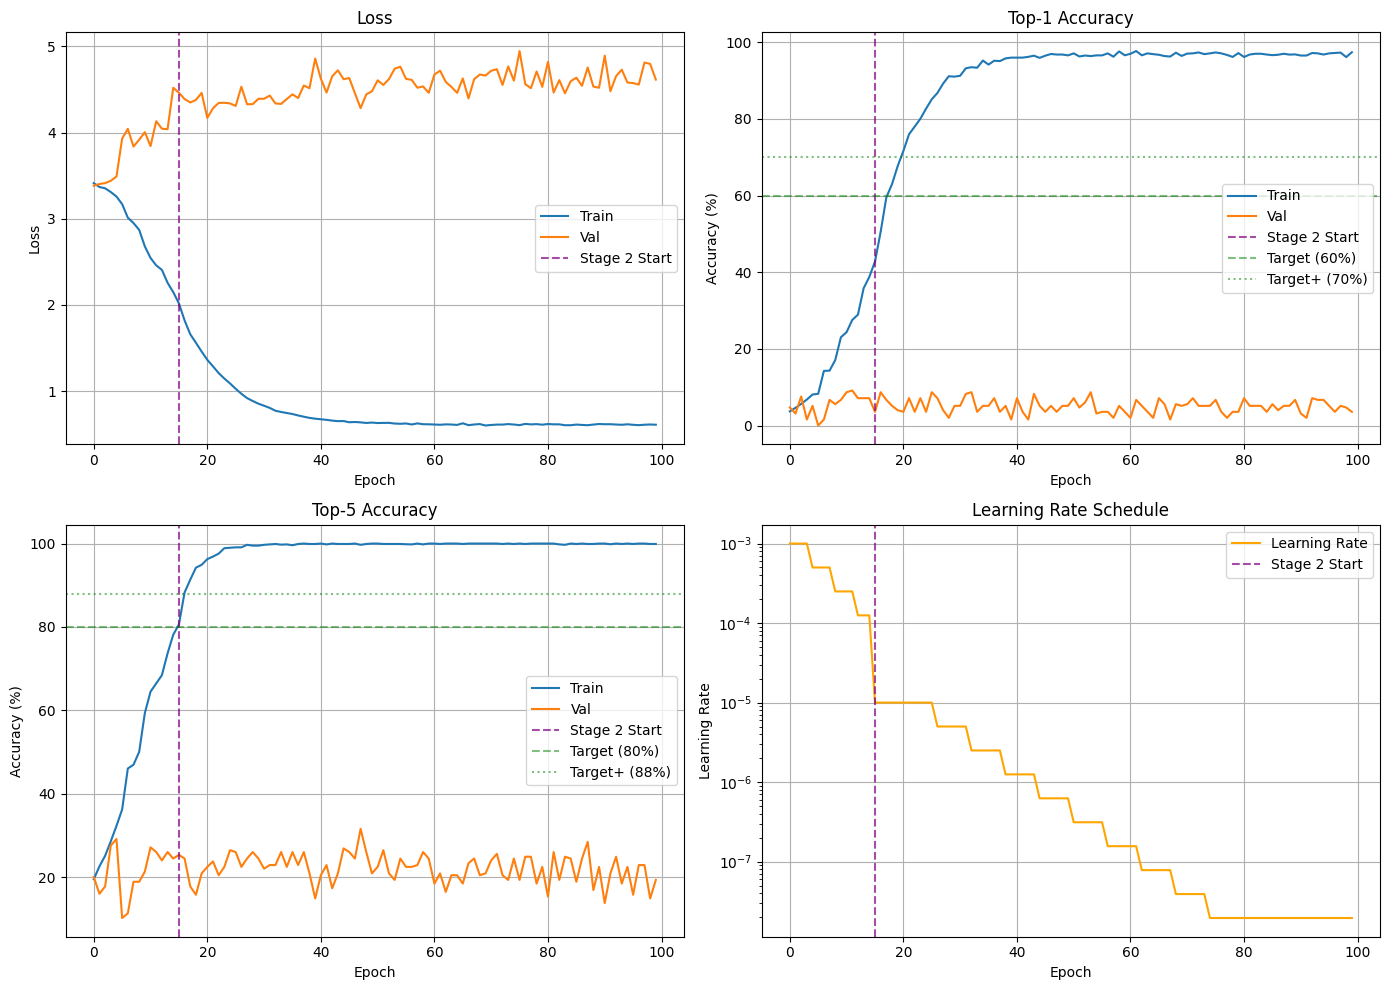

In [19]:
# Training curves with stage transition marker
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train')
axes[0, 0].plot(history['val_loss'], label='Val')
axes[0, 0].axvline(x=FREEZE_CNN_EPOCHS, color='purple', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Top-1 Accuracy
axes[0, 1].plot(history['train_top1'], label='Train')
axes[0, 1].plot(history['val_top1'], label='Val')
axes[0, 1].axvline(x=FREEZE_CNN_EPOCHS, color='purple', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[0, 1].axhline(y=60, color='g', linestyle='--', alpha=0.5, label='Target (60%)')
axes[0, 1].axhline(y=70, color='g', linestyle=':', alpha=0.5, label='Target+ (70%)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].set_title('Top-1 Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True)

# Top-5 Accuracy
axes[1, 0].plot(history['train_top5'], label='Train')
axes[1, 0].plot(history['val_top5'], label='Val')
axes[1, 0].axvline(x=FREEZE_CNN_EPOCHS, color='purple', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[1, 0].axhline(y=80, color='g', linestyle='--', alpha=0.5, label='Target (80%)')
axes[1, 0].axhline(y=88, color='g', linestyle=':', alpha=0.5, label='Target+ (88%)')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].set_title('Top-5 Accuracy')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Learning Rate (shows stage transition)
axes[1, 1].plot(history['lr'], label='Learning Rate', color='orange')
axes[1, 1].axvline(x=FREEZE_CNN_EPOCHS, color='purple', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_title('Learning Rate Schedule')
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(exp_dir / "training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# Load best model and evaluate with confusion matrix
checkpoint = torch.load(exp_dir / "best_model.pt")
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']}")

# Evaluate on validation with predictions
val_results = validate(
    model, val_loader, criterion, device, epoch=0,
    use_amp=USE_AMP, return_predictions=True
)

print(f"\nFinal validation results:")
print(f"  Top-1 Accuracy: {val_results['top1_acc']:.1f}%")
print(f"  Top-5 Accuracy: {val_results['top5_acc']:.1f}%")

Loaded best model from epoch 12


Epoch 0 [Val]:   0%|          | 0/2 [00:00<?, ?it/s]


Final validation results:
  Top-1 Accuracy: 9.1%
  Top-5 Accuracy: 26.1%


/tmp/ipython-input-3102840860.py:29: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


Confusion matrix saved to: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_twostage_20260131_022715/confusion_matrix.png


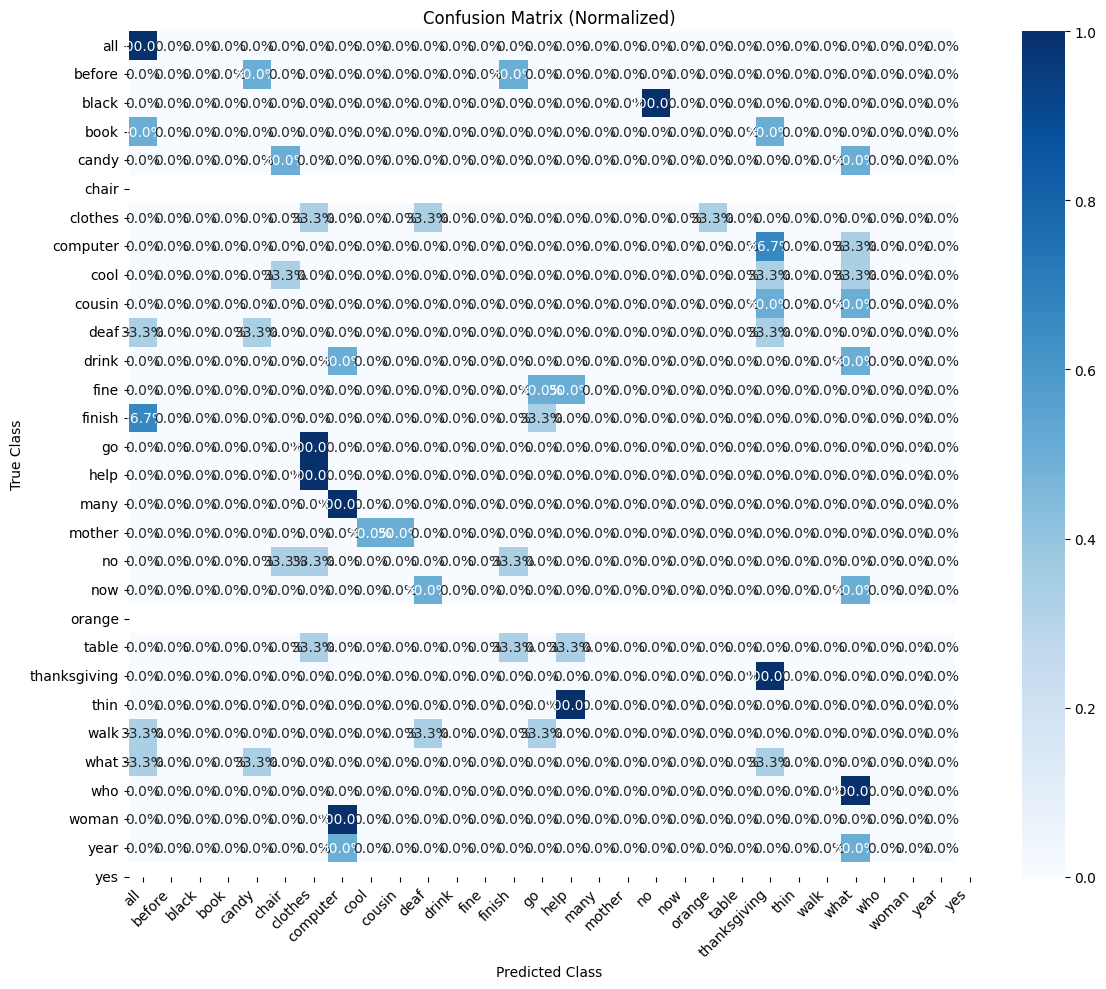

In [21]:
# Confusion Matrix
class_names = [val_dataset.get_gloss(i) for i in range(val_dataset.num_classes)]

plot_confusion_matrix(
    val_results['labels'],
    val_results['predictions'],
    class_names,
    save_path=str(exp_dir / "confusion_matrix.png")
)

## 10. Test Set Evaluation

In [22]:
# Create test loader
test_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="test",
    transform=get_transforms("test"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

# Evaluate
test_results = validate(
    model, test_loader, criterion, device, epoch=0,
    use_amp=USE_AMP, return_predictions=True
)

print(f"\n" + "=" * 60)
print("FINAL TEST SET RESULTS")
print("=" * 60)
print(f"Top-1 Accuracy: {test_results['top1_acc']:.1f}%")
print(f"Top-5 Accuracy: {test_results['top5_acc']:.1f}%")
print("=" * 60)

# Compare to targets
print(f"\nComparison to tutor targets:")
print(f"  Top-1: {test_results['top1_acc']:.1f}% (target: 60-70%)")
print(f"  Top-5: {test_results['top5_acc']:.1f}% (target: 80-88%)")

WLASLDataset [test]: 35 videos, 30 classes


Epoch 0 [Val]:   0%|          | 0/2 [00:00<?, ?it/s]


FINAL TEST SET RESULTS
Top-1 Accuracy: 1.6%
Top-5 Accuracy: 6.2%

Comparison to tutor targets:
  Top-1: 1.6% (target: 60-70%)
  Top-5: 6.2% (target: 80-88%)


In [23]:
# Save final results
final_results = {
    "experiment_name": EXPERIMENT_NAME,
    "best_epoch": best_epoch,
    "val_top1_acc": val_results['top1_acc'],
    "val_top5_acc": val_results['top5_acc'],
    "test_top1_acc": test_results['top1_acc'],
    "test_top5_acc": test_results['top5_acc'],
    "avg_peak_memory_gb": float(np.mean(history['peak_memory_gb'])),
    "optimizations_used": ["chunked_cnn", "amp"],
    "config": config
}

with open(exp_dir / "final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

print(f"\nResults saved to: {exp_dir}")
print("Generated files:")
for f in sorted(exp_dir.iterdir()):
    print(f"  - {f.name}")


Results saved to: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_twostage_20260131_022715
Generated files:
  - best_model.pt
  - checkpoint_epoch_10.pt
  - checkpoint_epoch_100.pt
  - checkpoint_epoch_15.pt
  - checkpoint_epoch_20.pt
  - checkpoint_epoch_30.pt
  - checkpoint_epoch_40.pt
  - checkpoint_epoch_50.pt
  - checkpoint_epoch_60.pt
  - checkpoint_epoch_70.pt
  - checkpoint_epoch_80.pt
  - checkpoint_epoch_90.pt
  - config.json
  - confusion_matrix.png
  - final_results.json
  - history.json
  - training_curves.png


## 11. Summary

### Two-Stage Training Strategy

| Stage | Epochs | CNN | Learning Rate | Purpose |
|-------|--------|-----|---------------|---------|
| 1 | 1-15 | Frozen | 1e-3 | LSTM learns temporal patterns from ImageNet features |
| 2 | 16-100 | Unfrozen | 1e-5 | CNN fine-tunes to hand-specific features |

### Why This Prevents Overfitting

1. **Stage 1**: CNN can't memorize training videos (frozen weights)
2. **Stage 1**: LSTM must learn actual temporal patterns to classify
3. **Stage 2**: CNN learns hand features WITHOUT memorizing (low LR)
4. **Stage 2**: LSTM already knows what to look for (guides CNN learning)

### Memory Optimizations

| Optimization | Impact |
|--------------|--------|
| Chunked CNN (64 frames/chunk) | Reduces peak activation memory |
| AMP (float16) | ~50% memory reduction, 2-3x faster |

### Expected Behavior

- **Stage 1**: Train accuracy rises slowly but steadily
- **Stage 1**: Val accuracy should follow train more closely
- **Stage 2**: Both may dip initially then recover
- **Target**: Val Top-1 60-70%, Val Top-5 80-88%